# 视觉变换样例库

[![下载Notebook](https://mindspore-website.obs.cn-north-4.myhuaweicloud.com/website-images/master/resource/_static/logo_notebook.svg)](https://mindspore-website.obs.cn-north-4.myhuaweicloud.com/notebook/master/docs/api_python/samples/dataset/vision_gallery.ipynb)&emsp;
[![查看源文件](https://mindspore-website.obs.cn-north-4.myhuaweicloud.com/website-images/master/resource/_static/logo_source.svg)](https://atomgit.com/mindspore/mindspore/blob/master/docs/api/api_python/samples/dataset/vision_gallery.ipynb)

此指南展示了[mindspore.dataset.vision](https://www.mindspore.cn/docs/zh-CN/master/api_python/mindspore.dataset.transforms.html#%E8%A7%86%E8%A7%89)模块中各种变换的用法。

## 环境准备

In [1]:
from download import download
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import numpy as np

import mindspore.dataset as ds
import mindspore.dataset.vision as vision
import mindspore.common.dtype as dtype

# Download opensource datasets
url = "https://mindspore-website.obs.cn-north-4.myhuaweicloud.com/notebook/datasets/flamingos.jpg"
download(url, './flamingos.jpg', replace=True)
orig_img = Image.open('flamingos.jpg')

# Env set for randomness and prepare plot function
ds.config.set_seed(66)

def plot(imgs, bbox_list=None, first_origin=True, **kwargs):
    num_rows = 1
    num_cols = len(imgs) + first_origin

    _, axs = plt.subplots(nrows=num_rows, ncols=num_cols, squeeze=False)
    if first_origin:
        imgs = [orig_img] + imgs
    for idx, img in enumerate(imgs):
        ax = axs[0, idx]
        if isinstance(img, np.ndarray) and img.shape[0] in [1, 3]:
            img = img.transpose(1, 2, 0)
        ax.imshow(img, **kwargs)
        ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

        if bbox_list:
            for bbox in bbox_list[idx]:
                rect = Rectangle((bbox[0], bbox[1]), bbox[2]-bbox[0], bbox[3]-bbox[1], linewidth=2, edgecolor='g', facecolor='none')
                ax.add_patch(rect)

    if first_origin:
        axs[0, 0].set(title='Original image')
        axs[0, 0].title.set_size(8)
    plt.tight_layout()


file_sizes: 100%|███████████████████████████| 45.8k/45.8k [00:00<00:00, 204kB/s]
Successfully downloaded file to ./flamingos.jpg


### Resize

[mindspore.dataset.vision.Resize](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.Resize.html#mindspore.dataset.vision.Resize) 会调整图像的尺寸大小。
对输入图像使用给定的 [mindspore.dataset.vision.Inter](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.Inter.html#mindspore.dataset.vision.Inter) 插值方式去调整为给定的尺寸大小。

In [5]:
resized_imgs = [vision.Resize(size=size, interpolation=vision.Inter.BICUBIC)(orig_img) for size in (30, 50, 100)]
plot(resized_imgs)

![Resize](images/Resize.png)

### CenterCrop

[mindspore.dataset.vision.CenterCrop](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.CenterCrop.html#mindspore.dataset.vision.CenterCrop) 会在图像中裁剪出中心区域。

In [10]:
center_crops = [vision.CenterCrop(size=size)(orig_img) for size in (30, 50, 100)]
plot(center_crops)

![CenterCrop](images/CenterCrop.png)

### RandomCrop

[mindspore.dataset.vision.RandomCrop](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.RandomCrop.html#mindspore.dataset.vision.RandomCrop) 会对输入图像进行随机区域的裁剪。



In [16]:
cropper = vision.RandomCrop(size=(128, 128))
crops = [cropper(orig_img) for _ in range(4)]
plot(crops)

![RandomCrop](images/RandomCrop.png)

### RandomCropDecodeResize

[mindspore.dataset.vision.RandomCropDecodeResize](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.RandomCropDecodeResize.html#mindspore.dataset.vision.RandomCropDecodeResize) 会对输入图像进行随机区域的裁剪、解码和调整大小。

In [17]:
img_to_ndarray = vision.ToNumpy()
img = img_to_ndarray(orig_img)
import io
import numpy as np

jpeg_buffer = io.BytesIO()
orig_img.save(jpeg_buffer, format="JPEG", quality=75)
encode_img = np.frombuffer(jpeg_buffer.getvalue(), dtype=np.uint8)
random_crop = vision.RandomCropDecodeResize(size=224, scale=(0.08, 1.0), ratio=(0.75, 1.333), interpolation=vision.Inter.LINEAR)
imgs = [random_crop(encode_img)]
plot(imgs)

![RandomCropDecodeResize](images/RandomCropDecodeResize.png)

### RandomResizedCrop

[mindspore.dataset.vision.RandomResizedCrop](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.RandomResizedCrop.html#mindspore.dataset.vision.RandomResizedCrop) 会对输入图像进行随机裁剪，并将裁剪区域调整为指定的尺寸大小。

In [19]:
resize_cropper = vision.RandomResizedCrop(size=(32, 32))
resized_crops = [resize_cropper(orig_img) for _ in range(4)]
plot(resized_crops)

![RandomResizedCrop](images/RandomResizedCrop.png)

## 光学变换

光学变换是指修改图像的测光属性，如其亮度、对比度、颜色或色调。这些变换的应用是为了改变图像的视觉外观，但保留其几何结构。

### Normalize

[mindspore.dataset.vision.Normalize](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.Normalize.html#mindspore.dataset.vision.Normalize) 用 $output[channel] = \frac{input[channel] - mean[channel]}{std[channel]} \quad 对于 \quad channel \geq 1$ 对输入图像进行归一化。

In [27]:
normalize = vision.Normalize(mean=[121.0, 115.0, 100.0], std=[70.0, 68.0, 71.0], is_hwc=True)
normalized_img = normalize(orig_img)
plot([normalized_img])

![Normalize](images/Normalize.png)

### Rescale

[mindspore.dataset.vision.Rescale](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.Rescale.html#mindspore.dataset.vision.Rescale) 将输入图像的像素值缩放到指定的范围。

In [32]:
rescale = vision.Rescale(1.0 / 128.0, -1.0)
rescaled_img = rescale(orig_img)
plot([rescaled_img])

![Rescale](images/Rescale.png)

### RandomColorAdjust

[mindspore.dataset.vision.RandomColorAdjust](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.RandomColorAdjust.html#mindspore.dataset.vision.RandomColorAdjust) 会随机调整输入图像的亮度、对比度、饱和度和色调。

In [36]:
jitter = vision.RandomColorAdjust(brightness=.5, hue=.3)
jitted_imgs = [jitter(orig_img) for _ in range(4)]
plot(jitted_imgs)

![RandomColorAdjust](images/RandomColorAdjust.png)

## 增强变换

以下的变换是多个变换的组合，通常来自论文提出的一些高效数据增强方法。

### ToTensor

[mindspore.dataset.vision.ToTensor](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.ToTensor.html#mindspore.dataset.vision.ToTensor) 会将PIL图像或Numpy数组转换为张量。

In [50]:
to_tensor = vision.ToTensor()
img = to_tensor(orig_img)
plot([img])

![ToTensor](images/ToTensor.png)

### HWC2CHW

[mindspore.dataset.vision.HWC2CHW](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.HWC2CHW.html#mindspore.dataset.vision.HWC2CHW) 会将输入图像的通道维度从HWC转换为CHW。

In [52]:
hsc2chw = vision.HWC2CHW()
img = [hsc2chw(orig_img)]
plot(img)

![HWC2CHW](images/HWC2CHW.png)

## 随机应用的变换

有些变换是以按照给定概率随机应用的。也就是说，转换后的图像可能与原始图像相同。

### RandomHorizontalFlip

[mindspore.dataset.vision.RandomHorizontalFlip](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.RandomHorizontalFlip.html#mindspore.dataset.vision.RandomHorizontalFlip)会对输入图像进行水平随机翻转。

In [63]:
hflipper = vision.RandomHorizontalFlip(0.5)
transformed_imgs = [hflipper(orig_img) for _ in range(4)]
plot(transformed_imgs)

![RandomHorizontalFlip](images/RandomHorizontalFlip.png)

### RandomVerticalFlip

[mindspore.dataset.vision.RandomVerticalFlip](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset_vision/mindspore.dataset.vision.RandomVerticalFlip.html#mindspore.dataset.vision.RandomVerticalFlip) 会对输入图像进行垂直随机翻转。

In [65]:
vflipper = vision.RandomVerticalFlip(0.5)
transformed_imgs = [vflipper(orig_img) for _ in range(4)]
plot(transformed_imgs)

![RandomVerticalFlip](images/RandomVerticalFlip.png)

## 在数据Pipeline中加载和处理图像文件

使用 [mindspore.dataset.ImageFolderDataset](https://www.mindspore.cn/docs/zh-CN/master/api_python/dataset/mindspore.dataset.ImageFolderDataset.html#mindspore.dataset.ImageFolderDataset) 将磁盘中的图像文件内容加载到数据Pipeline中，并进一步应用其他增强操作。


file_sizes: 100%|███████████████████████████| 45.7k/45.7k [00:00<00:00, 157kB/s]
Extracting zip file...
Successfully downloaded / unzipped to ./
column names: ['image', 'label']
>>>>> after decode
(64, 64, 3) 0
(64, 64, 3) 0
(64, 64, 3) 0
(64, 64, 3) 1
(64, 64, 3) 1
(64, 64, 3) 1
(64, 64, 3) 1
(64, 64, 3) 2
(64, 64, 3) 2
(64, 64, 3) 2
(64, 64, 3) 3
(64, 64, 3) 3
(64, 64, 3) 3
(64, 64, 3) 4
(64, 64, 3) 4
(64, 64, 3) 4
>>>>> after resize
(48, 48, 3) 0
(48, 48, 3) 0
(48, 48, 3) 0
(48, 48, 3) 1
(48, 48, 3) 1
(48, 48, 3) 1
(48, 48, 3) 1
(48, 48, 3) 2
(48, 48, 3) 2
(48, 48, 3) 2
(48, 48, 3) 3
(48, 48, 3) 3
(48, 48, 3) 3
(48, 48, 3) 4
(48, 48, 3) 4
(48, 48, 3) 4


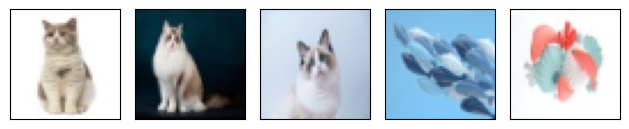

In [68]:
from download import download

import os
import mindspore.dataset as ds

# Download a small imagenet as example
url = "https://mindspore-website.obs.cn-north-4.myhuaweicloud.com/notebook/datasets/imageset.zip"
download(url, "./", kind="zip", replace=True)

# There are 5 classes in the image folder.
os.listdir("./imageset")

# Load these 5 classes into dataset pipeline
dataset = ds.ImageFolderDataset("./imageset", shuffle=False)

# check the column names inside the dataset. "image" column represents the image content and "label" column represents the corresponding label of image.
print("column names:", dataset.get_col_names())

# since the original image is not decoded, apply decode first on "image" column
dataset = dataset.map(vision.Decode(), input_columns=["image"])

# check results
print(">>>>> after decode")
for data, label in dataset:
    print(data.shape, label)

# let's do some transforms on dataset
# apply resize on images
dataset = dataset.map(vision.Resize(size=(48, 48)), input_columns=["image"])

# check results
print(">>>>> after resize")
images = []
for image, label in dataset:
    images.append(image.asnumpy())
    print(image.shape, label)

plot(images[:5], first_origin=False)